### Memanggil Library

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

#202431036_Fathur Rasyid Irimawa

#### Membaca Dataset dan Menampilkan datanya

In [2]:
df = pd.read_csv('tennis_courts (EDA).csv')
print(df.head(5))


#202431036_Fathur Rasyid Irimawa

   index               name               address city    state  \
0      0       Adelphi Road            washington   dc  20782.0   
1      1  Brandywood Circle               orlando   fl  32792.0   
2      2     Greenlee Drive     austin-san marcos   tx  78628.0   
3      3       McKee Street  minneapolis-st. paul   mn  55121.0   
4      4       Avenue North  minneapolis-st. paul   mn  55374.0   

               zip_code  type  count   clay   wall  grass  indoor  lights  \
0                Public     6  False   True  False  False   False   False   
1  Homeowners Community     1  False  False  False  False    True   False   
2                Public     8  False   True  False  False    True   False   
3                Public     1  False  False  False  False   False   False   
4                Public     6  False  False  False  False   False   False   

     proshop   latitude                                          longitude  
0  38.974351 -76.952112  {"clay"=>"0", "type"=>"Public", 

#### Melihat Informasi Data

In [3]:
df.info()

#202431036_Fathur Rasyid Irimawa

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29959 entries, 0 to 29958
Data columns (total 16 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   index      29959 non-null  int64  
 1   name       29959 non-null  object 
 2   address    29959 non-null  object 
 3   city       29959 non-null  object 
 4   state      29958 non-null  float64
 5   zip_code   29959 non-null  object 
 6   type       29959 non-null  int64  
 7   count      29959 non-null  bool   
 8   clay       29959 non-null  bool   
 9   wall       29959 non-null  bool   
 10  grass      29959 non-null  bool   
 11  indoor     29959 non-null  bool   
 12  lights     29959 non-null  bool   
 13  proshop    29959 non-null  float64
 14  latitude   29959 non-null  float64
 15  longitude  29959 non-null  object 
dtypes: bool(6), float64(3), int64(2), object(5)
memory usage: 2.5+ MB


#### Melihat Deskripsi Statistik

In [4]:
print(df.describe(include="all"))

#202431036_Fathur Rasyid Irimawa

               index         name   address   city         state zip_code  \
count   29959.000000        29959     29959  29959  29958.000000    29959   
unique           NaN        22313        54     30           NaN        2   
top              NaN  West Street  new york     ca           NaN   Public   
freq             NaN          212      2663   3864           NaN    16227   
mean    14979.000000          NaN       NaN    NaN  47890.646806      NaN   
std      8648.562694          NaN       NaN    NaN  29921.742686      NaN   
min         0.000000          NaN       NaN    NaN   1001.000000      NaN   
25%      7489.500000          NaN       NaN    NaN  27103.000000      NaN   
50%     14979.000000          NaN       NaN    NaN  38128.000000      NaN   
75%     22468.500000          NaN       NaN    NaN  77379.000000      NaN   
max     29958.000000          NaN       NaN    NaN  98685.000000      NaN   

                type  count   clay   wall  grass indoor lights       prosho

#### Meghitung Data yang kosong di setiap kolom

In [5]:
print(df.isna().sum())

#202431036_Fathur Rasyid Irimawa

index        0
name         0
address      0
city         0
state        1
zip_code     0
type         0
count        0
clay         0
wall         0
grass        0
indoor       0
lights       0
proshop      0
latitude     0
longitude    0
dtype: int64


#### Melihat isi kolom kategorik

In [6]:
cat_cols = df.select_dtypes(include=['object']).columns
for col in cat_cols:
    print(f"Nilai unik kolom '{col}': {df[col].unique()}")
    
#202431036_Fathur Rasyid Irimawa

Nilai unik kolom 'name': ['Adelphi Road' 'Brandywood Circle' 'Greenlee Drive' ... 'Bel Air Drive'
 'La Mirage Circle' 'Ledwicke Street']
Nilai unik kolom 'address': ['washington' 'orlando' 'austin-san marcos' 'minneapolis-st. paul'
 'west palm beach - boca raton' 'new york' 'chicago' 'denver' 'milwaukee'
 'atlanta' 'detroit' 'boston' 'baltimore' 'memphis' 'albany'
 'dayton-springfield' 'oklahoma city' 'st. louis'
 'san francisco - oakland - san jose' 'fresno' 'dallas - fort worth'
 'houston - galveston - brazoria' 'tampa-st. petersburg-clearwater'
 'san antonio' 'richmond-petersburg' 'cleveland' 'cincinnati'
 'raleigh-durham-chapel hill' 'grand rapids' 'indianapolis' 'los angeles'
 'philadelphia' 'seattle' 'pittsburgh' 'portland' 'miami-fort lauderdale'
 'nashville' 'wilmington-newark' 'hartford' 'louisville' 'kansas city'
 'phoenix' 'sacramento-yolo' 'jacksonville' 'rochester'
 'buffalo-niagara falls' 'norfolk-virginia beach' 'columbus' 'providence'
 'greensboro-winston-salem' 'charlo

#### Mengisi data kosong dengan modus untuk kategorik dan mean untuk angka

In [7]:
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
cat_cols = df.select_dtypes(include=['object', 'bool']).columns

for col in num_cols:
    df[col].fillna(df[col].mean(), inplace=True)

for col in cat_cols:
    df[col].fillna(df[col].mode()[0], inplace=True)

print("Data kosong setelah diisi:")
print(df.isna().sum())

#202431036_Fathur Rasyid Irimawa

Data kosong setelah diisi:
index        0
name         0
address      0
city         0
state        0
zip_code     0
type         0
count        0
clay         0
wall         0
grass        0
indoor       0
lights       0
proshop      0
latitude     0
longitude    0
dtype: int64


#### Menghitung Data yang duplikat

In [8]:
print("Jumlah duplikat:", df.duplicated().sum())

#202431036_Fathur Rasyid Irimawa

Jumlah duplikat: 0


#### Menghapus data duplikat kemudian di cek hasilnya

In [9]:
df = df.drop_duplicates()
df.info()

#202431036_Fathur Rasyid Irimawa

<class 'pandas.core.frame.DataFrame'>
Int64Index: 29959 entries, 0 to 29958
Data columns (total 16 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   index      29959 non-null  int64  
 1   name       29959 non-null  object 
 2   address    29959 non-null  object 
 3   city       29959 non-null  object 
 4   state      29959 non-null  float64
 5   zip_code   29959 non-null  object 
 6   type       29959 non-null  int64  
 7   count      29959 non-null  bool   
 8   clay       29959 non-null  bool   
 9   wall       29959 non-null  bool   
 10  grass      29959 non-null  bool   
 11  indoor     29959 non-null  bool   
 12  lights     29959 non-null  bool   
 13  proshop    29959 non-null  float64
 14  latitude   29959 non-null  float64
 15  longitude  29959 non-null  object 
dtypes: bool(6), float64(3), int64(2), object(5)
memory usage: 2.7+ MB


#### Visualisasi Data

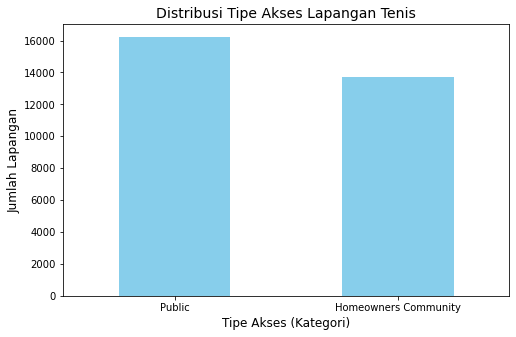

In [10]:
plt.figure(figsize=(8,5))

df['zip_code'].value_counts().plot(kind='bar', color='skyblue')

plt.title("Distribusi Tipe Akses Lapangan Tenis", fontsize=14)
plt.xlabel("Tipe Akses (Kategori)", fontsize=12)
plt.ylabel("Jumlah Lapangan", fontsize=12)
plt.xticks(rotation=0)
plt.show()

#202431036_Fathur Rasyid Irimawa